# découpage par volontaires et régression logistique de référence


In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

from charte_graphique import BLEU, ROUGE, BLANC, GRIS, appliquer_charte, teintes, CMAP_DIV
appliquer_charte()        # tous les graphiques suivent la charte

# Fixer la graine aléatoire : reproductibilité des expériences
def set_seed(seed=0):
    np.random.seed(seed)

set_seed(0)

### load data & encodage de la cible
comme on a fait à l'exploration

In [2]:
DATA_DIR = "../data/raw_har_data"
train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
test_df  = pd.read_csv(f"{DATA_DIR}/test.csv")

feature_cols = [c for c in train_df.columns if c not in ("subject", "Activity")]
classes = sorted(train_df["Activity"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}

X_all = train_df[feature_cols].to_numpy(dtype=np.float32)
y_all = train_df["Activity"].map(class_to_idx).to_numpy()
subject_all = train_df["subject"].to_numpy()

print("X_all :", X_all.shape, "| y_all :", y_all.shape, "| volontaires :", len(np.unique(subject_all)))

X_all : (7352, 561) | y_all : (7352,) | volontaires : 21



## Découpage apprentissage / validation par volontaires

Au test, les volontaires sont **nouveaux** : la validation doit imiter cette situation. On réserve donc 5 volontaires entiers de `train.csv`.


In [3]:
subjects = np.sort(np.unique(subject_all))
rng = np.random.default_rng(0)
val_subjects = np.sort(rng.choice(subjects, size=5, replace=False))
is_val = np.isin(subject_all, val_subjects)

X_train, y_train = X_all[~is_val], y_all[~is_val]
X_val,   y_val   = X_all[is_val],  y_all[is_val]

print("volontaires de validation :", val_subjects.tolist())
print("volontaires d'apprentissage :", len(subjects) - len(val_subjects))
print(f"apprentissage : {len(y_train)} fenêtres | validation : {len(y_val)} fenêtres ({len(y_val) / len(y_all):.1%})")
print("fenêtres par volontaire de validation :")
print(pd.Series(subject_all[is_val]).value_counts().sort_index().to_string())

# On sauvegarde le découpage pour que les notebooks suivants utilisent exactement les mêmes volontaires
with open("../data/split_volontaires.json", "w") as f:
    json.dump({"val_subjects": [int(s) for s in val_subjects], "seed": 0}, f)

volontaires de validation : [8, 11, 16, 19, 23]
volontaires d'apprentissage : 16
apprentissage : 5657 fenêtres | validation : 1695 fenêtres (23.1%)
fenêtres par volontaire de validation :
8     281
11    316
16    366
19    360
23    372


Chaque volontaire a fait les six activités ; la validation doit donc contenir toutes les classes, dans des proportions voisines de celles de l'apprentissage.

findfont: Failed to find font weight semibold for Arial, now using 700.


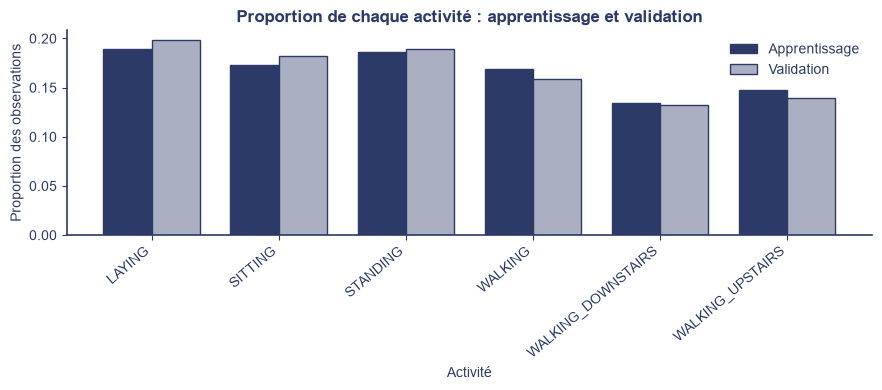

nombre d'exemples par classe en validation : [336 309 320 269 224 237]


In [4]:
prop_train = np.bincount(y_train, minlength=len(classes)) / len(y_train)
prop_val   = np.bincount(y_val,   minlength=len(classes)) / len(y_val)

x = np.arange(len(classes)); w = 0.38
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - w / 2, prop_train, w, label="Apprentissage", color=BLEU, edgecolor=BLEU)
ax.bar(x + w / 2, prop_val,   w, label="Validation", color=teintes(2, 0.6)[1], edgecolor=BLEU)
ax.set_xticks(x); ax.set_xticklabels(classes, rotation=40, ha="right")
ax.set_title("Proportion de chaque activité : apprentissage et validation")
ax.set_xlabel("Activité"); ax.set_ylabel("Proportion des observations"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print("nombre d'exemples par classe en validation :", np.bincount(y_val, minlength=len(classes)))

### Standardisation
standardisation **sur l'apprentissage uniquement**, puis appliqués à la validation (et plus tard au test).
-> to prevent data leakage

In [7]:
mu = X_train.mean(axis=0)
sd = X_train.std(axis=0)
sd[sd == 0] = 1.0                      # division par zéro (FI)

def standardise(X):
    return ((X - mu) / sd).astype(np.float32)

X_train_s, X_val_s = standardise(X_train), standardise(X_val)
X_test_s = standardise(test_df[feature_cols].to_numpy(dtype=np.float32))
y_test = test_df["Activity"].map(class_to_idx).to_numpy()

print("apprentissage : moyenne des moyennes =", X_train_s.mean(axis=0).mean().round(4), "| écart-type moyen =", X_train_s.std(axis=0).mean().round(4))
print("validation    : moyenne des moyennes =", X_val_s.mean(axis=0).mean().round(4), "| écart-type moyen =", X_val_s.std(axis=0).mean().round(4))

apprentissage : moyenne des moyennes = 0.0 | écart-type moyen = 1.0
validation    : moyenne des moyennes = 0.0716 | écart-type moyen = 1.2092


In [8]:
# Sauvegarde des données standardisées
import os

DOSSIER = "../data/processed_har_data"
os.makedirs(DOSSIER, exist_ok=True)

def vers_csv(X_s, y, subject, nom):
    df = pd.DataFrame(X_s, columns=feature_cols)
    df["subject"] = subject
    df["Activity"] = np.array(classes)[y]          
    df.to_csv(f"{DOSSIER}/{nom}.csv", index=False, float_format="%.9g")
    print(f"{nom}.csv sauvegardé :", os.path.getsize(f"{DOSSIER}/{nom}.csv") // 1024, "Ko")

vers_csv(X_train_s, y_train, subject_all[~is_val], "train_processed")
vers_csv(X_val_s,   y_val,   subject_all[is_val],  "val_processed")
vers_csv(X_test_s,  y_test,  test_df["subject"].to_numpy(), "test_processed")

# On garde aussi mu et sd (calculés sur le train), utiles pour standardiser de nouvelles données
pd.DataFrame({"variable": feature_cols, "mean": mu, "std": sd}).to_csv(
    f"{DOSSIER}/standardisation_stats.csv", index=False)


train_processed.csv sauvegardé : 38259 Ko
val_processed.csv sauvegardé : 11448 Ko
test_processed.csv sauvegardé : 19951 Ko



On entraîne la même régression logistique deux fois :
-  avec un découpage par volontaires
- avec un découpage aléatoire de lignes, de même proportion de validation.

Chaque modèle est évalué sur sa propre validation.

In [ ]:
def fit_logreg(X, y):
    mu_, sd_ = X.mean(axis=0), X.std(axis=0); sd_[sd_ == 0] = 1.0
    clf = LogisticRegression(max_iter=500).fit((X - mu_) / sd_, y)
    return clf, mu_, sd_

def eval_logreg(clf, mu_, sd_, X, y):
    pred = clf.predict((X - mu_) / sd_)
    return accuracy_score(y, pred), f1_score(y, pred, average="macro"), pred

#  découpage par volontaires
clf_sub, mu_sub, sd_sub = fit_logreg(X_train, y_train)
acc_sub, f1_sub, pred_sub = eval_logreg(clf_sub, mu_sub, sd_sub, X_val, y_val)

#  découpage aléatoire de lignes
train_idx, val_idx = train_test_split(np.arange(len(X_all)), test_size=is_val.mean(), stratify=y_all, random_state=0)
clf_rnd, mu_rnd, sd_rnd = fit_logreg(X_all[train_idx], y_all[train_idx])
acc_rnd, f1_rnd, _ = eval_logreg(clf_rnd, mu_rnd, sd_rnd, X_all[val_idx], y_all[val_idx])

comparaison = pd.DataFrame({"accuracy (validation)": [acc_rnd, acc_sub], "F1 macro (validation)": [f1_rnd, f1_sub]},
                           index=["lignes aléatoires", "volontaires entiers"])
display(comparaison.round(4))

,accuracy (validation),F1 macro (validation)
lignes aléatoires,0.9870,0.9879
volontaires entiers,0.9168,0.9187


**Remarques** Le découpage aléatoire donne de meilleurs scores (accuracy 0,987 ; F1 macro 0,988) que le découpage par volontaires (0,917 ; 0,919), mais ce gain est artificiel. Les fenêtres se chevauchent de 50 % et un même volontaire apparaît dans l’apprentissage et la validation : Avec un découpage aléatoire, la validation contient presque des copies de fenêtres du train. Le modèle les « reconnaît » plus qu’il ne généralise, et le score est gonflé. C’est la fuite de données dont on a parlé.
l'écart de 7 points est la taille de lafuite 

Le découpage par volontaires évalue la généralisation à de nouvelles personnes, ce qui correspond au test final. Nous retenons donc ce dernier comme référence, avec une accuracy de validation d’environ 0,92 -> estimation plus honnéte.

## Référence : la régression logistique

In [11]:
print(f"Régression logistique (validation par volontaires) : accuracy = {acc_sub:.4f} | F1 macro = {f1_sub:.4f}\n")
print(classification_report(y_val, pred_sub, target_names=classes, digits=3))

Régression logistique (validation par volontaires) : accuracy = 0.9168 | F1 macro = 0.9187

                    precision    recall  f1-score   support

            LAYING      0.973     0.976     0.975       336
           SITTING      0.819     0.926     0.869       309
          STANDING      0.921     0.806     0.860       320
           WALKING      0.871     0.981     0.923       269
WALKING_DOWNSTAIRS      0.967     0.924     0.945       224
  WALKING_UPSTAIRS      0.995     0.890     0.940       237

          accuracy                          0.917      1695
         macro avg      0.925     0.917     0.919      1695
      weighted avg      0.922     0.917     0.917      1695



### 2.2 Matrice de confusion sur la validation
Chaque ligne est une activité réelle, chaque colonne l'activité prédite : la diagonale contient les bonnes réponses. Les valeurs sont en proportion de chaque ligne.

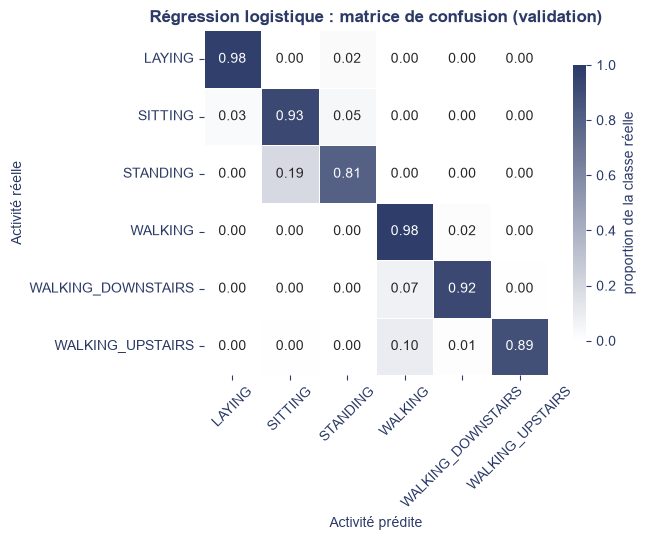

In [12]:
cm = confusion_matrix(y_val, pred_sub)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
cmap_bleu = LinearSegmentedColormap.from_list("charte_bleu", [BLANC, BLEU])

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap=cmap_bleu, vmin=0, vmax=1, square=True,
            linewidths=0.5, linecolor=BLANC, xticklabels=classes, yticklabels=classes,
            cbar_kws={"label": "proportion de la classe réelle", "shrink": 0.8}, ax=ax)
ax.set_title("Régression logistique : matrice de confusion (validation)")
ax.set_xlabel("Activité prédite"); ax.set_ylabel("Activité réelle")
ax.tick_params(axis="x", labelrotation=45)
plt.tight_layout(); plt.show()

les confusions sont entre:
- STANDING et SITTING
- WALKING ET LA MARCHE EN ESCLAIER
LAYING est presque parfaite